# Sneha Singh
## DATA 266 — Homework 4.5
BERT sentiment fine-tune, then training throughput and memory on one GPU

Run this on a Colab GPU. The first cell mounts My Drive, and the last cell copies the run into `MyDrive/HW-4.5`.


In [1]:
# Colab: install packages and mount Drive. On my Mac this cell does nothing.
import shutil
from pathlib import Path

try:
    import google.colab
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

DRIVE_FOLDER_NAME = "HW-4.5"
DRIVE_DIR = (Path("/content/drive/MyDrive") / DRIVE_FOLDER_NAME) if IN_COLAB else None

if IN_COLAB:
    import subprocess
    import sys
    subprocess.check_call([
        sys.executable, "-m", "pip", "install", "-q",
        "transformers>=4.40", "datasets>=2.18", "accelerate>=0.30",
        "bitsandbytes>=0.43", "sentencepiece", "protobuf", "matplotlib",
    ])
    try:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "vllm"])
    except subprocess.CalledProcessError:
        print("vLLM did not install. Section 6 will record the import error.")
    from google.colab import drive
    drive.mount("/content/drive")
    # folder name on Drive so the download is one click: MyDrive/HW-4.5
    DRIVE_DIR = Path("/content/drive/MyDrive") / "HW-4.5"
    DRIVE_DIR.mkdir(parents=True, exist_ok=True)
    print("Drive folder:", DRIVE_DIR)
    print("download this folder from Google Drive as HW-4.5")
else:
    print("not Colab. files stay in this folder.")

def save_to_drive():
    # copy into MyDrive/HW-4.5. Safe to run more than once.
    if not IN_COLAB or DRIVE_DIR is None:
        print("local run. files stay in", ROOT)
        return
    DRIVE_DIR.mkdir(parents=True, exist_ok=True)
    print("saving into Drive folder:", DRIVE_DIR.name)
    for name in ("METRICS.md", "RUN_LOG.txt", "AI_USE.md", "README.md", "requirements.txt"):
        src = ROOT / name
        if src.exists():
            shutil.copy2(src, DRIVE_DIR / name)
    for folder in ("figures", "checkpoints", "data", "reservations"):
        src = ROOT / folder
        if src.exists() and any(src.iterdir()):
            shutil.copytree(src, DRIVE_DIR / folder, dirs_exist_ok=True)
    for nb_path in Path("/content").glob("*.ipynb"):
        shutil.copy2(nb_path, DRIVE_DIR / nb_path.name)
    print("saved to", DRIVE_DIR)
    for path in sorted(p for p in DRIVE_DIR.rglob("*") if p.is_file()):
        print(f"  {path.relative_to(DRIVE_DIR)}  ({path.stat().st_size} bytes)")


Mounted at /content/drive
Drive folder: /content/drive/MyDrive/HW-4.5
download this folder from Google Drive as HW-4.5


In [2]:
# Step 0: Libraries & Student Parameters
import gc
import json
import random
import re
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
from torch.utils.data import DataLoader, Dataset

# Colab works in /content, then save_to_drive copies it. Local uses this folder.
if "IN_COLAB" in dir() and IN_COLAB:
    ROOT = Path("/content/HW-4.5")
elif Path.cwd().name == "HW-4.5":
    ROOT = Path.cwd()
else:
    ROOT = Path.cwd() / "HW-4.5"

DATA_DIR = ROOT / "data"
FIG_DIR = ROOT / "figures"
CKPT_DIR = ROOT / "checkpoints"
DATA_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR.mkdir(parents=True, exist_ok=True)
CKPT_DIR.mkdir(parents=True, exist_ok=True)

# last 4 of my SJSUid - 0670
SID4 = 670
SEED = SID4
SLICE = SID4 % 1000
HP_ID = SID4 % 6
CLS_A = SID4 % 10
CLS_B = (CLS_A + 1 + ((SID4 // 10) % 9)) % 10

# set seeds for python, numpy, torch
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("mps" if torch.backends.mps.is_available() else ("cuda" if torch.cuda.is_available() else "cpu"))

# HW4.a settings. Later sections change one of these at a time.
LABELS = ["negative", "neutral", "positive"]
MODEL_NAME = "bert-base-uncased"
MAX_LENGTH = 128
BASE_BATCH = 16
EPOCHS = 3
LR = 2e-5
WEIGHT_DECAY = 0.01
WARMUP_RATIO = 0.1
SERVE_MODEL = "facebook/opt-125m"
MAX_NEW_TOKENS = 32
ACCUM_PHYSICAL = 8
ACCUM_STEPS = 16
BATCH_LADDER = [8, 16, 32, 64, 128, 256, 512, 1024, 2048, 4096]

LOG = []

def note(line):
    print(line)
    LOG.append(str(line))

def need_cuda(what):
    if device.type != "cuda":
        print(f"{what}: this kernel is {device}. The memory and vLLM numbers need a CUDA GPU.")
        return False
    return True

print("SID4: ", SID4)
print("SEED: ", SEED)
print("SLICE:", SLICE)
print("HP_ID:", HP_ID)
print("CLS_A:", CLS_A)
print("CLS_B:", CLS_B)
print("Device:", device)
print("ROOT:  ", ROOT)
if "DRIVE_DIR" in dir() and DRIVE_DIR is not None:
    print("Drive:", DRIVE_DIR)
else:
    print("Drive: local folder")
if device.type == "cuda":
    print("GPU:   ", torch.cuda.get_device_name(0))


SID4:  670
SEED:  670
SLICE: 670
HP_ID: 4
CLS_A: 0
CLS_B: 5
Device: cuda
ROOT:   /content/HW-4.5
Drive: /content/drive/MyDrive/HW-4.5
GPU:    NVIDIA L4


This assignment said follow the same step 0 as assignment 1. I did not copy the HW1 diabetes notebook. I only reused the standing parameters: SID4=670, SEED=670, SLICE=670, HP_ID=4, CLS_A=0, CLS_B=5, and I seeded python / numpy / torch with 670.

HP_ID is reported only. There is no second network. Part C is skipped. The October 23 note says it is optional, and one GPU is enough.

The data cells run anywhere. The fine-tune, the batch ladder, and vLLM need CUDA, because those sections are measuring GPU memory.
I am running the measured cells on Colab. The first cell mounts My Drive. The baseline cell and the last cell copy `METRICS.md`, `RUN_LOG.txt`, `figures/`, and `checkpoints/` to `MyDrive/HW-4.5`. On my Mac those cells leave the files in this folder.


## 1. Data

5,000 consecutive rows from the `tweet_eval` sentiment train split, starting at row 670. I do not use that dataset's own validation or test split. SEED 670 then splits these rows 70/15/15.


In [3]:
# load the frozen slice. Do not reshuffle before the row cut.
slice_path = DATA_DIR / "twitter_slice.jsonl"
saved_slice = None
if "DRIVE_DIR" in dir() and DRIVE_DIR is not None:
    saved_slice = DRIVE_DIR / "data" / "twitter_slice.jsonl"
if not slice_path.exists() and saved_slice is not None and saved_slice.exists():
    slice_path.write_bytes(saved_slice.read_bytes())
    print("copied slice from Drive")
if slice_path.exists():
    rows = [json.loads(line) for line in slice_path.read_text().splitlines() if line.strip()]
    print("loaded", slice_path.name)
else:
    from datasets import load_dataset
    raw = load_dataset("cardiffnlp/tweet_eval", "sentiment", split="train")
    end = min(SLICE + 5000, len(raw))
    rows = [{"row_index": i, "text": raw[i]["text"], "label": int(raw[i]["label"])} for i in range(SLICE, end)]
    slice_path.write_text("".join(json.dumps(r, ensure_ascii=False) + "\n" for r in rows))
    print("wrote", slice_path.name)

def counts(part):
    found = {name: 0 for name in LABELS}
    for row in part:
        found[LABELS[int(row["label"])]] += 1
    return found

print(f"rows {rows[0]['row_index']} to {rows[-1]['row_index']}   n={len(rows)}")
print("slice label counts", counts(rows))
print("example", rows[0]["row_index"], rows[0]["text"][:180])


README.md:   0%|          | 0.00/23.9k [00:00<?, ?B/s]

sentiment/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 3.78MB            

sentiment/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

sentiment/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  901kB            

sentiment/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

...

sentiment/validation-00000-of-00001.parq(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/45615 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/12284 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/2000 [00:00<?, ? examples/s]

wrote twitter_slice.jsonl
rows 670 to 5669   n=5000
slice label counts {'negative': 773, 'neutral': 2290, 'positive': 1937}
example 670 "The 2nd act released onto the FUTURE-ONE line up is the massive ORGAN DONORS! 30th November @ City Nightclub, Falkirk. #Nutcases"


In [4]:
# 70/15/15 split with SEED. The slice itself is not shuffled before this.
idx = np.arange(len(rows))
rng = np.random.default_rng(SEED)
rng.shuffle(idx)
n_train = int(len(rows) * 0.70)
n_val = int(len(rows) * 0.15)
train_rows = [rows[i] for i in idx[:n_train]]
val_rows = [rows[i] for i in idx[n_train:n_train + n_val]]
test_rows = [rows[i] for i in idx[n_train + n_val:]]
print(f"train / val / test  {len(train_rows)} / {len(val_rows)} / {len(test_rows)}")
print("train counts", counts(train_rows))


train / val / test  3500 / 750 / 750
train counts {'negative': 533, 'neutral': 1630, 'positive': 1337}


## 2. Tokenizer and batches

`BertTokenizer`. Every tweet is padded to 128 tokens, so the memory of a step depends on the batch size and not on which tweets landed in it.


In [5]:
# BertTokenizer and a dataset of padded length-128 rows
from transformers import BertForSequenceClassification, BertTokenizer

tokenizer = BertTokenizer.from_pretrained(MODEL_NAME)

class Encoded(Dataset):
    def __init__(self, encodings, labels):
        self.enc = encodings
        self.labels = labels

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, i):
        item = {
            k: torch.tensor(self.enc[k][i])
            for k in ("input_ids", "attention_mask", "token_type_ids")
            if k in self.enc
        }
        item["labels"] = torch.tensor(int(self.labels[i]))
        return item

def encode(part):
    texts = [row["text"] for row in part]
    labels = [int(row["label"]) for row in part]
    enc = tokenizer(texts, truncation=True, padding="max_length", max_length=MAX_LENGTH)
    return Encoded(enc, labels), texts

def make_loader(dataset, batch_size, shuffle):
    generator = None
    if shuffle:
        generator = torch.Generator()
        generator.manual_seed(SEED)
    return DataLoader(
        dataset,
        batch_size=batch_size,
        shuffle=shuffle,
        generator=generator,
        num_workers=0,
        pin_memory=(device.type == "cuda"),
    )

def repeat_to(part, n):
    # a memory probe needs a full batch, even when the batch is larger than the training set
    if len(part) >= n:
        return part[:n]
    reps = (n + len(part) - 1) // len(part)
    return (part * reps)[:n]

print("tokenizer vocab", tokenizer.vocab_size, "  pad", MAX_LENGTH)


tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

tokenizer vocab 30522   pad 128


## 3. Training step

Same loop for the baseline and for every later section. `mode="full"` is the 3-epoch fine-tune. `mode="epoch"` is one pass, for time per epoch. `mode="probe"` is one step on a full batch, for the memory wall. `mode="steps"` runs a set number of optimizer steps, for gradient accumulation.


In [6]:
# one-line note for a misclassified tweet. It has to match the words in the tweet.
POS_WORDS = ("love", "loved", "great", "amazing", "awesome", "happy", "best", "good", "win", "won", "excellent", "nice", "glad", "fun")
NEG_WORDS = ("hate", "hated", "worst", "bad", "sad", "terrible", "awful", "ugly", "angry", "stupid", "sucks", "horrible", "fail", "failed")

def one_line(text, true_name, pred_name):
    raw = " ".join(text.split())
    tokens = set(re.findall(r"[a-z']+", raw.lower()))
    pos = next((word for word in POS_WORDS if word in tokens), None)
    neg = next((word for word in NEG_WORDS if word in tokens), None)
    if true_name == "negative" and pred_name == "positive" and pos:
        reason = f'the word "{pos}" is in a negative tweet, and the model followed that word'
    elif true_name == "positive" and pred_name == "negative" and neg:
        reason = f'the word "{neg}" is in a positive tweet, and the model followed that word'
    elif re.search(r"\b(not|no|never|n't)\b", raw.lower()):
        reason = "a negation flips the polarity, and the model missed it"
    elif re.search(r"\b(but|though|however)\b", raw.lower()):
        reason = "the tweet changes direction mid-sentence"
    elif "http" in raw.lower() or raw.count("@") >= 2:
        reason = "most of the tweet is a link or a handle, so there is little sentiment text"
    elif len(raw.split()) <= 4:
        reason = "the tweet is only a few words, so the class is under-specified"
    elif true_name == "neutral":
        reason = f"it reads like a flat statement, and the model called it {pred_name}"
    else:
        reason = f"the wording is closer to a {pred_name} tweet than a clear {true_name} one"
    return f"Labeled {true_name}, predicted {pred_name}: {reason}."

def class_report(y_true, y_pred, texts):
    cm = np.zeros((3, 3), dtype=int)
    for true_i, pred_i in zip(y_true, y_pred):
        cm[int(true_i), int(pred_i)] += 1
    per_class = []
    for c in range(3):
        support = int(cm[c].sum())
        predicted = int(cm[:, c].sum())
        tp = int(cm[c, c])
        per_class.append({
            "label": LABELS[c],
            "precision": tp / predicted if predicted else 0.0,
            "recall": tp / support if support else 0.0,
            "support": support,
        })
    worst = sorted(per_class, key=lambda row: (row["recall"], row["precision"], row["support"]))[0]["label"]
    worst_id = LABELS.index(worst)
    examples = []
    for i, (true_i, pred_i) in enumerate(zip(y_true, y_pred)):
        if int(true_i) == worst_id and int(pred_i) != worst_id:
            examples.append({
                "text": texts[i],
                "true": LABELS[int(true_i)],
                "predicted": LABELS[int(pred_i)],
                "diagnosis": one_line(texts[i], LABELS[int(true_i)], LABELS[int(pred_i)]),
            })
        if len(examples) == 5:
            break
    return {"confusion_matrix": cm.tolist(), "per_class": per_class, "worst_class": worst, "misclassified": examples}


In [7]:
# forward, backward, and one optimizer step. AMP and accumulation are flags, not a second model.
def optimizer_step(model, optimizer, scheduler, scaler, micro):
    if scaler is not None:
        scaler.unscale_(optimizer)
    if micro > 1:
        for param in model.parameters():
            if param.grad is not None:
                param.grad.div_(micro)
    torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
    if scaler is not None:
        scaler.step(optimizer)
        scaler.update()
    else:
        optimizer.step()
    if scheduler is not None:
        scheduler.step()
    optimizer.zero_grad(set_to_none=True)

def train_pass(model, loader, optimizer, scheduler, scaler, amp_dtype, accum_steps, max_steps):
    model.train()
    loss_sum, n_seen, opt_steps, micro = 0.0, 0, 0, 0
    optimizer.zero_grad(set_to_none=True)
    use_amp = amp_dtype is not None
    torch.cuda.synchronize()
    t0 = time.perf_counter()
    while True:
        progressed, stop = False, False
        for batch in loader:
            progressed = True
            batch = {k: v.to(device) for k, v in batch.items()}
            bs = int(batch["labels"].size(0))
            with torch.autocast(device_type="cuda", dtype=amp_dtype or torch.float32, enabled=use_amp):
                out = model(**batch)
                loss = out.loss
            if scaler is not None:
                scaler.scale(loss).backward()
            else:
                loss.backward()
            loss_sum += float(out.loss.detach()) * bs
            n_seen += bs
            micro += 1
            if micro == accum_steps:
                optimizer_step(model, optimizer, scheduler, scaler, micro)
                micro = 0
                opt_steps += 1
                if opt_steps % 50 == 0:
                    print(f"    step {opt_steps}  samples {n_seen}", flush=True)
                if max_steps is not None and opt_steps >= max_steps:
                    stop = True
                    break
        if micro and not stop:
            optimizer_step(model, optimizer, scheduler, scaler, micro)
            opt_steps += 1
        if stop or max_steps is None or not progressed:
            break
    torch.cuda.synchronize()
    seconds = time.perf_counter() - t0
    return {
        "train_loss": loss_sum / max(n_seen, 1),
        "seconds": seconds,
        "samples": n_seen,
        "optimizer_steps": opt_steps,
        "samples_per_sec": n_seen / seconds if seconds else 0.0,
    }


In [8]:
# test or validation pass. No dropout.
@torch.no_grad()
def evaluate(model, loader):
    model.eval()
    loss_sum, n = 0.0, 0
    preds, labels = [], []
    for batch in loader:
        gold = batch["labels"]
        batch = {k: v.to(device) for k, v in batch.items()}
        out = model(**batch)
        bs = int(gold.size(0))
        loss_sum += float(out.loss.detach()) * bs
        n += bs
        preds.append(out.logits.argmax(-1).cpu())
        labels.append(gold.cpu())
    y_pred = torch.cat(preds).numpy()
    y_true = torch.cat(labels).numpy()
    return {
        "loss": loss_sum / max(n, 1),
        "accuracy": float((y_pred == y_true).mean()),
        "y_true": y_true,
        "y_pred": y_pred,
    }

def make_optimizer(model, name):
    if name == "adamw8bit":
        import bitsandbytes as bnb
        return bnb.optim.AdamW8bit(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
    return torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)

def is_oom(exc):
    return type(exc).__name__ == "OutOfMemoryError" or "out of memory" in str(exc).lower()


In [9]:
# run one fine-tune from bert-base. Returns the losses, the peak memory, and the test score.
def fine_tune(tag, batch_size=BASE_BATCH, epochs=EPOCHS, amp=False, checkpoint=False, accum_steps=1, optimizer_name="adamw", mode="full", max_steps=None, save=False):
    random.seed(SEED)
    np.random.seed(SEED)
    torch.manual_seed(SEED)
    torch.cuda.manual_seed_all(SEED)
    part = train_rows
    if mode == "probe":
        part = repeat_to(train_rows, batch_size)
        epochs = 1
        max_steps = 1
    elif mode in ("epoch", "steps"):
        epochs = 1
    model = BertForSequenceClassification.from_pretrained(MODEL_NAME, num_labels=3).to(device)
    if checkpoint:
        model.config.use_cache = False
        model.gradient_checkpointing_enable()
    train_ds, _ = encode(part)
    train_loader = make_loader(train_ds, batch_size, shuffle=(mode != "probe"))
    optimizer = make_optimizer(model, optimizer_name)
    steps_per_epoch = max(1, int(np.ceil(len(train_ds) / float(batch_size * accum_steps))))
    planned = int(max_steps) if mode in ("probe", "steps") and max_steps else steps_per_epoch * epochs
    warmup = max(1, int(planned * WARMUP_RATIO))
    scheduler = torch.optim.lr_scheduler.LambdaLR(
        optimizer,
        lambda step: ((step + 1) / warmup) if step < warmup else max(0.0, (planned - step) / max(1, planned - warmup)),
    )
    bf16 = amp and torch.cuda.is_bf16_supported()
    amp_dtype = torch.bfloat16 if bf16 else (torch.float16 if amp else None)
    scaler = torch.amp.GradScaler("cuda") if amp_dtype == torch.float16 else None
    torch.cuda.empty_cache()
    torch.cuda.reset_peak_memory_stats()
    history, best_state, best_epoch, best_val = [], None, None, None
    train_seconds = train_samples = opt_steps = 0
    try:
        for epoch in range(1, epochs + 1):
            limit = 1 if mode == "probe" else (max_steps if mode == "steps" else None)
            stats = train_pass(model, train_loader, optimizer, scheduler, scaler, amp_dtype, accum_steps, limit)
            train_seconds += stats["seconds"]
            train_samples += stats["samples"]
            opt_steps += stats["optimizer_steps"]
            row = {"epoch": epoch, **stats}
            if mode == "full":
                val_ds, _ = encode(val_rows)
                val = evaluate(model, make_loader(val_ds, batch_size, False))
                row["val_loss"] = val["loss"]
                row["val_accuracy"] = val["accuracy"]
                if best_val is None or val["loss"] < best_val:
                    best_val = val["loss"]
                    best_epoch = epoch
                    best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
                print(f"epoch {epoch}  train {stats['train_loss']:.4f}  val {val['loss']:.4f}  acc {val['accuracy']:.4f}  {stats['seconds']:.1f}s")
            history.append(row)
    except RuntimeError as exc:
        del model
        gc.collect()
        torch.cuda.empty_cache()
        if is_oom(exc):
            return {"tag": tag, "oom": True, "error": str(exc), "batch_size": batch_size}
        raise
    result = {
        "tag": tag,
        "oom": False,
        "batch_size": batch_size,
        "accum_steps": accum_steps,
        "effective_batch": batch_size * accum_steps,
        "history": history,
        "train_seconds": train_seconds,
        "train_samples": train_samples,
        "optimizer_steps": opt_steps,
        "samples_per_sec": train_samples / train_seconds if train_seconds else 0.0,
        "peak_allocated_gb": torch.cuda.max_memory_allocated() / (1024 ** 3),
        "best_val_loss_epoch": best_epoch,
        "best_val_loss": best_val,
    }
    if mode == "full":
        test_ds, test_texts = encode(test_rows)
        test_loader = make_loader(test_ds, batch_size, False)
        final = evaluate(model, test_loader)
        result["test_final"] = {"loss": final["loss"], "accuracy": final["accuracy"], **class_report(final["y_true"], final["y_pred"], test_texts)}
        if best_state is not None:
            model.load_state_dict(best_state)
        best = evaluate(model, test_loader)
        result["test_best_val_epoch"] = {"loss": best["loss"], "accuracy": best["accuracy"], "epoch": best_epoch, **class_report(best["y_true"], best["y_pred"], test_texts)}
        if save:
            dest = CKPT_DIR / "bert_baseline"
            model.save_pretrained(dest)
            tokenizer.save_pretrained(dest)
            reloaded = BertForSequenceClassification.from_pretrained(dest).to(device).eval()
            custom = [
                "I love this, it made my whole day.",
                "This is the worst update they have shipped.",
                "The package arrived today.",
            ]
            enc = tokenizer(custom, truncation=True, padding=True, max_length=MAX_LENGTH, return_tensors="pt")
            enc = {k: v.to(device) for k, v in enc.items()}
            with torch.no_grad():
                pred = reloaded(**enc).logits.argmax(-1).cpu().tolist()
            result["reloaded_inference"] = [{"text": text, "predicted": LABELS[i]} for text, i in zip(custom, pred)]
            del reloaded
    del model, optimizer
    gc.collect()
    torch.cuda.empty_cache()
    return result

print("training step ready")


training step ready


## 4. HW4.a baseline

Batch 16, AdamW, learning rate 2e-5, 3 epochs. I keep the epoch with the lowest validation loss and score the test set there. If a later epoch is worse, the extra seconds are the cost of training past that point.


In [10]:
# HW4.a fine-tune. Peak memory and wall-clock time from this cell are the HW4.5 baseline.
if need_cuda("baseline"):
    baseline_run = fine_tune("baseline", batch_size=BASE_BATCH, epochs=EPOCHS, save=True)
    test = baseline_run.get("test_best_val_epoch") or {}
    note(f"baseline seconds={baseline_run.get('train_seconds')} peak_gb={baseline_run.get('peak_allocated_gb')} test_acc={test.get('accuracy')}")
    for row in baseline_run.get("history") or []:
        note(f"epoch {row['epoch']} train={row['train_loss']:.4f} val={row.get('val_loss')} acc={row.get('val_accuracy')} seconds={row['seconds']:.1f}")
    save_to_drive()


config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  440MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


    step 50  samples 800
    step 100  samples 1600
    step 150  samples 2400
    step 200  samples 3200
epoch 1  train 0.8892  val 0.7410  acc 0.6640  37.0s
    step 50  samples 800
    step 100  samples 1600
    step 150  samples 2400
    step 200  samples 3200
epoch 2  train 0.5950  val 0.7395  acc 0.6773  37.8s
    step 50  samples 800
    step 100  samples 1600
    step 150  samples 2400
    step 200  samples 3200
epoch 3  train 0.3922  val 0.7976  acc 0.6813  38.3s


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

baseline seconds=113.13704028099983 peak_gb=2.4768271446228027 test_acc=0.7266666666666667
epoch 1 train=0.8892 val=0.7410369749069214 acc=0.664 seconds=37.0
epoch 2 train=0.5950 val=0.7394668963750204 acc=0.6773333333333333 seconds=37.8
epoch 3 train=0.3922 val=0.7976047325134278 acc=0.6813333333333333 seconds=38.3
saving into Drive folder: HW-4.5
saved to /content/drive/MyDrive/HW-4.5
  checkpoints/bert_baseline/config.json  (969 bytes)
  checkpoints/bert_baseline/model.safetensors  (437961700 bytes)
  checkpoints/bert_baseline/tokenizer.json  (711661 bytes)
  checkpoints/bert_baseline/tokenizer_config.json  (351 bytes)
  data/twitter_slice.jsonl  (761653 bytes)


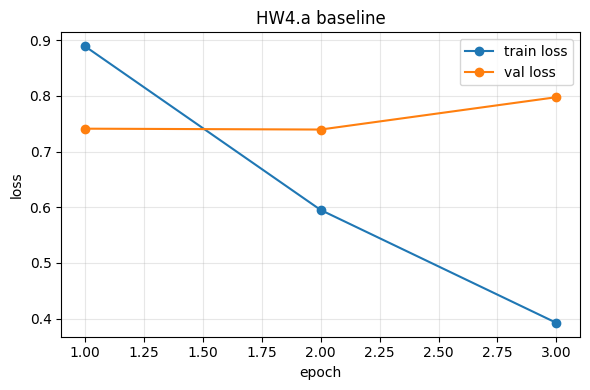

In [11]:
# loss curve
if "baseline_run" in dir() and not baseline_run.get("oom"):
    hist = baseline_run["history"]
    plt.figure(figsize=(6, 4))
    plt.plot([row["epoch"] for row in hist], [row["train_loss"] for row in hist], marker="o", label="train loss")
    plt.plot([row["epoch"] for row in hist], [row["val_loss"] for row in hist], marker="o", label="val loss")
    plt.xlabel("epoch")
    plt.ylabel("loss")
    plt.title("HW4.a baseline")
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.savefig(FIG_DIR / "baseline_loss.png", dpi=140)
    plt.show()
else:
    print("loss curve waits for the baseline run")


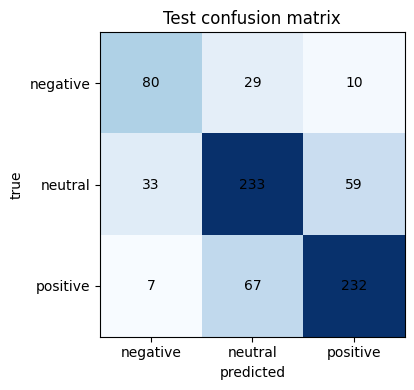

worst class: negative
negative    precision 0.6667  recall 0.6723  support 119
neutral     precision 0.7082  recall 0.7169  support 325
positive    precision 0.7708  recall 0.7582  support 306


In [12]:
# confusion matrix on the test set, at the best validation-loss epoch
if "baseline_run" in dir() and baseline_run.get("test_best_val_epoch"):
    test = baseline_run["test_best_val_epoch"]
    cm = np.array(test["confusion_matrix"])
    plt.figure(figsize=(5, 4))
    plt.imshow(cm, cmap="Blues")
    plt.xticks(range(3), LABELS)
    plt.yticks(range(3), LABELS)
    plt.xlabel("predicted")
    plt.ylabel("true")
    plt.title("Test confusion matrix")
    for i in range(3):
        for j in range(3):
            plt.text(j, i, str(cm[i, j]), ha="center", va="center")
    plt.tight_layout()
    plt.savefig(FIG_DIR / "confusion.png", dpi=140)
    plt.show()
    print("worst class:", test["worst_class"])
    for row in test["per_class"]:
        print(f"{row['label']:10s}  precision {row['precision']:.4f}  recall {row['recall']:.4f}  support {row['support']}")
else:
    print("confusion matrix waits for the baseline run")


In [13]:
# five misclassified tweets from the worst class, with a one-line note each
if "baseline_run" in dir() and baseline_run.get("test_best_val_epoch"):
    for i, example in enumerate(baseline_run["test_best_val_epoch"]["misclassified"], 1):
        print(f"{i}. {example['text']}")
        print("  ", example["diagnosis"])
        note(f"misclassified {i}: {example['diagnosis']}")
else:
    print("examples wait for the baseline run")


1. "Sophos is the Lamest Virus Ever...: Starting September 19, Sophos successfully became the lamest... |InfoSecIsland"
   Labeled negative, predicted neutral: the wording is closer to a neutral tweet than a clear negative one.
misclassified 1: Labeled negative, predicted neutral: the wording is closer to a neutral tweet than a clear negative one.
2. Because she's Caitlyn Jenner. Come to FL sistah where you can run someone over with no consequences.
   Labeled negative, predicted neutral: a negation flips the polarity, and the model missed it.
misclassified 2: Labeled negative, predicted neutral: a negation flips the polarity, and the model missed it.
3. Tonight may be the night when I finally expose myself to the Gilmore Girls hysteria
   Labeled negative, predicted neutral: the wording is closer to a neutral tweet than a clear negative one.
misclassified 3: Labeled negative, predicted neutral: the wording is closer to a neutral tweet than a clear negative one.
4. Monday was Gucci but

In [14]:
# save, reload, and classify three sentences that were not in the test split
if "baseline_run" in dir() and baseline_run.get("reloaded_inference"):
    for row in baseline_run["reloaded_inference"]:
        print(row["predicted"], " ", row["text"])
        note(f"reload {row['predicted']}: {row['text']}")
else:
    print("reload waits for the baseline run")


positive   I love this, it made my whole day.
reload positive: I love this, it made my whole day.
negative   This is the worst update they have shipped.
reload negative: This is the worst update they have shipped.
neutral   The package arrived today.
reload neutral: The package arrived today.


## 5. Hugging Face pipeline, batch 1

The serving model is `facebook/opt-125m`, not BERT. The first prompt is mine. The other 31 stay fixed so every batch size sees the same text. This cell is the pipeline baseline: one request at a time, greedy, 32 new tokens.


In [15]:
# fixed prompts. Index 0 is the one I wrote.
OWN_PROMPT = (
    "Explain in two sentences why a larger batch can raise tokens per second "
    "while one person waits longer for a reply."
)
PROMPTS = [
    OWN_PROMPT,
    "What is a confusion matrix used for?",
    "Give one reason a validation loss can go up while training loss goes down.",
    "Name three Twitter sentiment labels.",
    "How does gradient accumulation build a larger effective batch?",
    "Why does gradient checkpointing recompute activations?",
    "What does p95 latency mean for a chat app?",
    "Write a one-sentence summary of mixed precision training.",
    "Why is a fixed VRAM ratio a poor guess for the max batch ratio?",
    "What is the KV cache storing during generation?",
    "A user asks for a short weather report. Reply in one sentence.",
    "Explain tokens per second in plain language.",
    "Why pad tweets to a fixed length when measuring GPU memory?",
    "What is the difference between throughput and latency?",
    "Give a short example of a negative tweet and a positive tweet.",
    "Why should an interactive demo care more about latency than tokens per second?",
    "What does AdamW change compared with Adam?",
    "How do you know a fine-tune trained past the best validation epoch?",
    "What is BERT's job in a sentiment classifier?",
    "Why reload a saved model before custom inference?",
    "Name one thing that stays fixed between the HW4.a run and HW4.5.",
    "What is an out-of-memory error on a GPU?",
    "Why does a power-of-two batch ladder miss some sizes?",
    "Describe peak allocated memory in one sentence.",
    "A student has one GPU. What should they write if Part C is optional?",
    "Why is the same seed used for the train, validation, and test split?",
    "What does batch size 1 mean for a Hugging Face pipeline?",
    "How can a server finish more tokens per second and still feel slower to one user?",
    "What is bfloat16 useful for on a recent NVIDIA GPU?",
    "Give a careful definition of recall for one class.",
    "Why is a link-only tweet hard to classify?",
    "State one limit of a 3-epoch BERT fine-tune on 3,500 tweets.",
]
assert len(PROMPTS) == 32

def summarise(latencies_ms, tokens, wall):
    return {
        "tokens_per_sec": (tokens / wall) if wall else 0.0,
        "p50_ms": float(np.percentile(latencies_ms, 50)),
        "p95_ms": float(np.percentile(latencies_ms, 95)),
        "n": len(latencies_ms),
    }


In [16]:
# HF pipeline, batch 1. Generated tokens per second, plus p50 and p95 of the request time.
serving = {}
if need_cuda("HF pipeline"):
    from transformers import pipeline
    try:
        pipe = pipeline("text-generation", model=SERVE_MODEL, torch_dtype=torch.float16, device=0)
    except TypeError:
        pipe = pipeline("text-generation", model=SERVE_MODEL, dtype=torch.float16, device=0)
    tok = pipe.tokenizer
    pipe(PROMPTS[0], max_new_tokens=4, do_sample=False)
    latencies, tokens = [], 0
    torch.cuda.synchronize()
    t_wall = time.perf_counter()
    for prompt in PROMPTS:
        torch.cuda.synchronize()
        t0 = time.perf_counter()
        out = pipe(prompt, max_new_tokens=MAX_NEW_TOKENS, do_sample=False, return_full_text=False)
        torch.cuda.synchronize()
        latencies.append((time.perf_counter() - t0) * 1000)
        tokens += len(tok.encode(out[0]["generated_text"], add_special_tokens=False))
    serving["hf_batch1"] = summarise(latencies, tokens, time.perf_counter() - t_wall)
    note("HF pipeline batch 1  " + json.dumps(serving["hf_batch1"]))
    del pipe
    gc.collect()
    torch.cuda.empty_cache()


config.json:   0%|          | 0.00/651 [00:00<?, ?B/s]

[transformers] `torch_dtype` is deprecated! Use `dtype` instead!


pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  251MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

...

model.safetensors: reconstructing file:   0%|          |  0.00B /  251MB            

model.safetensors: downloading bytes:           |  0.00B            

special_tokens_map.json:   0%|          | 0.00/441 [00:00<?, ?B/s]

[transformers] Passing `generation_config` together with generation-related arguments=({'max_new_tokens', 'do_sample'}) is deprecated and will be removed in future versions. Please pass either a `generation_config` object OR all generation parameters explicitly, but not both.
[transformers] Both `max_new_tokens` (=4) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Ignoring clean_up_tokenization_spaces=True for BPE tokenizer GPT2Tokenizer. The clean_up_tokenization post-processing step is designed for WordPiece tokenizers and is destructive for BPE (it strips spaces before punctuation). Set clean_up_tokenization_spaces=False to suppress this warning, or set clean_up_tokenization_spaces_for_bpe_even_though_it_will_corrupt_output=True to force cleanup anyway.
[transformers] Both `max_new_tokens` (=32) and

HF pipeline batch 1  {"tokens_per_sec": 115.66951114356566, "p50_ms": 269.31953849998536, "p95_ms": 280.81388469945523, "n": 32}


## 6. vLLM at batch 1, 8, and 32

Same prompts, same 32 new tokens. I run the table twice on this GPU. The first pass is the HW4.a serving table. The second pass is Part D. vLLM needs a Linux GPU. If the import fails, the error stays in the log.


In [17]:
# vLLM batches. Per-request latency is the wait for that batch, because the requests return together.
if need_cuda("vLLM"):
    try:
        from vllm import LLM, SamplingParams

        def generate(llm, prompts, params):
            try:
                return llm.generate(prompts, params, use_tqdm=False)
            except TypeError:
                return llm.generate(prompts, params)

        def one_pass(tag):
            llm = LLM(model=SERVE_MODEL, dtype="float16", max_model_len=2048, gpu_memory_utilization=0.90, enforce_eager=True)
            params = SamplingParams(temperature=0, max_tokens=MAX_NEW_TOKENS)
            generate(llm, [PROMPTS[0]], SamplingParams(temperature=0, max_tokens=4))
            rows = {}
            for batch, repeats in ((1, 1), (8, 2), (32, 4)):
                prompts = PROMPTS * repeats
                latencies, tokens, wall = [], 0, 0.0
                for start in range(0, len(prompts), batch):
                    group = prompts[start:start + batch]
                    torch.cuda.synchronize()
                    t0 = time.perf_counter()
                    outs = generate(llm, group, params)
                    torch.cuda.synchronize()
                    dt = time.perf_counter() - t0
                    wall += dt
                    for item in outs:
                        tokens += len(item.outputs[0].token_ids)
                        latencies.append(dt * 1000)
                rows[batch] = summarise(latencies, tokens, wall)
                note(f"vLLM {tag} batch {batch}  " + json.dumps(rows[batch]))
            del llm
            gc.collect()
            torch.cuda.empty_cache()
            return rows

        serving["vllm_hw4a"] = one_pass("hw4a")
        serving["vllm_hw45"] = one_pass("hw45")
    except Exception as exc:
        serving["vllm_error"] = f"{type(exc).__name__}: {exc}"
        note("vLLM did not run: " + serving["vllm_error"])


(MainProcess pid=26746) INFO 10-26 21:56:59 [api_utils.py:286] non-default args: {'dtype': 'float16', 'max_model_len': 2048, 'gpu_memory_utilization': 0.9, 'disable_log_stats': True, 'enforce_eager': True, 'model': 'facebook/opt-125m'}
(MainProcess pid=26746) INFO 10-26 21:57:15 [model.py:733] Resolved architecture: OPTForCausalLM
(MainProcess pid=26746) INFO 10-26 21:57:15 [model.py:2152] Using max model len 2048
(MainProcess pid=26746) INFO 10-26 21:57:15 [scheduler.py:307] Chunked prefill is enabled with max_num_batched_tokens=8192.
(MainProcess pid=26746) WARNING 10-26 21:57:16 [config.py:1384] Could not retrieve safetensors metadata for facebook/opt-125m (Hub fetch failed and the cached snapshot holds no weights yet).
(MainProcess pid=26746) WARNING 10-26 21:57:16 [vllm.py:1703] Enforce eager set, disabling torch.compile, CUDAGraphs, and JIT kernel warmup. This is equivalent to setting -cc.mode=none -cc.cudagraph_mode=none and --kernel_config.enable_jit_warmup=False
(MainProcess p

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 9 files:   0%|          | 0/9 [00:00<?, ?it/s]

(MainProcess pid=26746) WARNING 10-26 21:57:17 [system_utils.py:153] We must use the `spawn` multiprocessing start method. Overriding VLLM_WORKER_MULTIPROC_METHOD to 'spawn'. See https://docs.vllm.ai/en/latest/usage/troubleshooting.html#python-multiprocessing for more information. Reasons: CUDA is initialized
(MainProcess pid=26746) INFO 10-26 21:57:39 [hf.py:648] Detected the chat template content format to be 'string'. You can set `--chat-template-content-format` to override this.
vLLM hw4a batch 1  {"tokens_per_sec": 97.77896359903848, "p50_ms": 319.1171024996038, "p95_ms": 328.3780902500439, "n": 32}
vLLM hw4a batch 8  {"tokens_per_sec": 627.7876585577313, "p50_ms": 349.1526440002417, "p95_ms": 354.8725029995694, "n": 64}
vLLM hw4a batch 32  {"tokens_per_sec": 2273.497231108878, "p50_ms": 383.69950599962976, "p95_ms": 386.47891899927345, "n": 128}
(MainProcess pid=26746) INFO 10-26 21:57:54 [utils.py:628] [shutdown] Process manager: send sigterm to process EngineCore
(MainProcess p

## Part A — batch scaling

Same fine-tune as section 4. The batch doubles until one forward and backward on exactly that many length-128 rows runs out of memory. Each size that fits also gets one pass over the training rows. That pass is the time per epoch.


In [18]:
# double the batch until the step runs out of memory
part_a = []
if need_cuda("Part A"):
    for batch in BATCH_LADDER:
        probe = fine_tune(f"probe_{batch}", batch_size=batch, mode="probe")
        if probe.get("oom"):
            part_a.append({"batch_size": batch, "oom": True})
            note(f"part A batch {batch} out of memory")
            break
        epoch = fine_tune(f"epoch_{batch}", batch_size=batch, mode="epoch")
        part_a.append({
            "batch_size": batch,
            "oom": False,
            "epoch_samples_per_sec": epoch["samples_per_sec"],
            "epoch_seconds": epoch["train_seconds"],
            "epoch_peak_gb": epoch["peak_allocated_gb"],
        })
        note(f"part A batch {batch}  {epoch['samples_per_sec']:.1f} samp/s  {epoch['peak_allocated_gb']:.2f} GB  {epoch['train_seconds']:.1f}s")


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


    step 50  samples 400
    step 100  samples 800
    step 150  samples 1200
    step 200  samples 1600
    step 250  samples 2000
    step 300  samples 2400
    step 350  samples 2800
    step 400  samples 3200
part A batch 8  70.5 samp/s  2.09 GB  49.7s


...

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


part A batch 256  121.0 samp/s  20.65 GB  28.9s


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


part A batch 512 out of memory


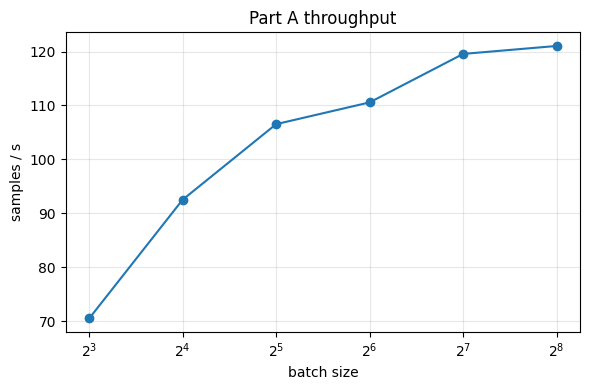

largest batch that ran: 256
fastest batch: 256 121.0 samp/s


In [19]:
# throughput against batch size
ok = [row for row in part_a if not row.get("oom")] if "part_a" in dir() else []
if ok:
    plt.figure(figsize=(6, 4))
    plt.plot([row["batch_size"] for row in ok], [row["epoch_samples_per_sec"] for row in ok], marker="o")
    plt.xscale("log", base=2)
    plt.xlabel("batch size")
    plt.ylabel("samples / s")
    plt.title("Part A throughput")
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.savefig(FIG_DIR / "part_a_throughput.png", dpi=140)
    plt.show()
    best = max(ok, key=lambda row: row["epoch_samples_per_sec"])
    print("largest batch that ran:", ok[-1]["batch_size"])
    print("fastest batch:", best["batch_size"], f"{best['epoch_samples_per_sec']:.1f} samp/s")
else:
    print("Part A plot waits for the CUDA run")


## Part B — mixed precision

One change from the baseline: bfloat16 autocast when the card has it, otherwise float16 with a grad scaler. The 3-epoch train stays at batch 16 so the accuracy can be compared. The max batch is a separate probe.


In [20]:
# mixed precision, alone
part_b = {}

def probe_max_batch(**flags):
    last = None
    for batch in BATCH_LADDER:
        probe = fine_tune("wall", batch_size=batch, mode="probe", **flags)
        if probe.get("oom"):
            return last, batch
        last = batch
    return last, None

if need_cuda("mixed precision") and "baseline_run" in dir():
    wall, oom_at = probe_max_batch(amp=True)
    run = fine_tune("amp", amp=True)
    part_b["amp"] = {
        "name": "Mixed precision",
        "max_batch": wall,
        "oom_at": oom_at,
        "samples_per_sec": run.get("samples_per_sec"),
        "train_seconds": run.get("train_seconds"),
        "peak_allocated_gb": run.get("peak_allocated_gb"),
        "test_accuracy": (run.get("test_best_val_epoch") or {}).get("accuracy"),
    }
    note(f"amp max_batch={wall} samp/s={run.get('samples_per_sec')} peak={run.get('peak_allocated_gb')} acc={part_b['amp']['test_accuracy']}")


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

...

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


    step 50  samples 800
    step 100  samples 1600
    step 150  samples 2400
    step 200  samples 3200
epoch 1  train 0.8871  val 0.7674  acc 0.6427  18.6s
    step 50  samples 800
    step 100  samples 1600
    step 150  samples 2400
    step 200  samples 3200
epoch 2  train 0.5926  val 0.7562  acc 0.6733  18.5s
    step 50  samples 800
    step 100  samples 1600
    step 150  samples 2400
    step 200  samples 3200
epoch 3  train 0.3858  val 0.8324  acc 0.6640  18.4s
amp max_batch=256 samp/s=189.3168024983808 peak=2.260280132293701 acc=0.704


## Part B — gradient checkpointing

Activations are recomputed on the backward pass. This should use less memory and fewer samples per second. Same batch-16 train, then its own max-batch probe.


In [21]:
# gradient checkpointing, alone
if need_cuda("gradient checkpointing") and "baseline_run" in dir():
    wall, oom_at = probe_max_batch(checkpoint=True)
    run = fine_tune("checkpoint", checkpoint=True)
    part_b["checkpoint"] = {
        "name": "Gradient checkpointing",
        "max_batch": wall,
        "oom_at": oom_at,
        "samples_per_sec": run.get("samples_per_sec"),
        "train_seconds": run.get("train_seconds"),
        "peak_allocated_gb": run.get("peak_allocated_gb"),
        "test_accuracy": (run.get("test_best_val_epoch") or {}).get("accuracy"),
    }
    note(f"checkpoint max_batch={wall} samp/s={run.get('samples_per_sec')} peak={run.get('peak_allocated_gb')} acc={part_b['checkpoint']['test_accuracy']}")


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

...

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


    step 50  samples 800
    step 100  samples 1600
    step 150  samples 2400
    step 200  samples 3200
epoch 1  train 0.8892  val 0.7410  acc 0.6640  49.6s
    step 50  samples 800
    step 100  samples 1600
    step 150  samples 2400
    step 200  samples 3200
epoch 2  train 0.5950  val 0.7395  acc 0.6773  49.4s
    step 50  samples 800
    step 100  samples 1600
    step 150  samples 2400
    step 200  samples 3200
epoch 3  train 0.3922  val 0.7976  acc 0.6813  49.6s
checkpoint max_batch=1024 samp/s=70.6853206668266 peak=2.0878524780273438 acc=0.7266666666666667


## Part B — 8-bit AdamW

Optimizer states in 8 bits. If `bitsandbytes` does not import, that failure is the result for this row.


In [22]:
# 8-bit AdamW, alone
if need_cuda("8-bit AdamW") and "baseline_run" in dir():
    try:
        wall, oom_at = probe_max_batch(optimizer_name="adamw8bit")
        run = fine_tune("adam8bit", optimizer_name="adamw8bit")
        part_b["adam8bit"] = {
            "name": "8-bit optimiser",
            "max_batch": wall,
            "oom_at": oom_at,
            "samples_per_sec": run.get("samples_per_sec"),
            "train_seconds": run.get("train_seconds"),
            "peak_allocated_gb": run.get("peak_allocated_gb"),
            "test_accuracy": (run.get("test_best_val_epoch") or {}).get("accuracy"),
        }
        note(f"8-bit max_batch={wall} samp/s={run.get('samples_per_sec')} peak={run.get('peak_allocated_gb')} acc={part_b['adam8bit']['test_accuracy']}")
    except Exception as exc:
        part_b["adam8bit"] = {"name": "8-bit optimiser", "failed": True, "error": f"{type(exc).__name__}: {exc}"}
        note("8-bit did not run: " + part_b["adam8bit"]["error"])


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

...

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


    step 50  samples 800
    step 100  samples 1600
    step 150  samples 2400
    step 200  samples 3200
epoch 1  train 0.8909  val 0.7352  acc 0.6627  35.7s
    step 50  samples 800
    step 100  samples 1600
    step 150  samples 2400
    step 200  samples 3200
epoch 2  train 0.5957  val 0.7569  acc 0.6773  35.0s
    step 50  samples 800
    step 100  samples 1600
    step 150  samples 2400
    step 200  samples 3200
epoch 3  train 0.3902  val 0.8159  acc 0.6893  35.0s
8-bit max_batch=256 samp/s=99.27705440234733 peak=1.8966383934020996 acc=0.7186666666666667


## Part B — gradient accumulation

Physical batch 8, 16 accumulation steps, so the effective batch is 128. One run is 3 epochs, for accuracy. A second run uses the same number of optimizer steps as the baseline, for wall-clock time. The lower peak here is the smaller physical batch, not a separate memory trick.


In [23]:
# gradient accumulation: small physical batch, effective batch 128
if need_cuda("gradient accumulation") and "baseline_run" in dir():
    run = fine_tune("accum", batch_size=ACCUM_PHYSICAL, accum_steps=ACCUM_STEPS)
    timed = fine_tune(
        "accum_steps",
        batch_size=ACCUM_PHYSICAL,
        accum_steps=ACCUM_STEPS,
        mode="steps",
        max_steps=baseline_run["optimizer_steps"],
    )
    part_b["accum"] = {
        "name": "Gradient accumulation",
        "max_batch": ACCUM_PHYSICAL * ACCUM_STEPS,
        "samples_per_sec": run.get("samples_per_sec"),
        "train_seconds": run.get("train_seconds"),
        "peak_allocated_gb": run.get("peak_allocated_gb"),
        "test_accuracy": (run.get("test_best_val_epoch") or {}).get("accuracy"),
        "same_steps": baseline_run["optimizer_steps"],
        "same_steps_seconds": timed.get("train_seconds"),
    }
    note(f"accum effective {ACCUM_PHYSICAL * ACCUM_STEPS} same-step seconds={timed.get('train_seconds')} acc={part_b['accum']['test_accuracy']}")


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


epoch 1  train 1.0231  val 0.9656  acc 0.5013  35.6s
epoch 2  train 0.8814  val 0.8562  acc 0.6053  35.1s
epoch 3  train 0.7715  val 0.8184  acc 0.6093  34.9s


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


    step 50  samples 6268
    step 100  samples 12404
    step 150  samples 18540
    step 200  samples 24676
    step 250  samples 31072
    step 300  samples 37208
    step 350  samples 43344
    step 400  samples 49480
    step 450  samples 55748
    step 500  samples 62012
    step 550  samples 68148
    step 600  samples 74284
accum effective 128 same-step seconds=816.8813488930009 acc=0.652


## Part B — combination

Score is memory saved per sample/s lost, at batch 16. A technique that saves memory without slowing down ranks first. Accumulation is not in the combination. Checkpointing is added only if it saves at least 2 GB.


In [24]:
# pick the combination from the three batch-16 runs, then train it
if need_cuda("combination") and "baseline_run" in dir() and part_b:
    base_sps = baseline_run["samples_per_sec"]
    base_gb = baseline_run["peak_allocated_gb"]
    scored = []
    for key in ("amp", "checkpoint", "adam8bit"):
        row = part_b.get(key) or {}
        if row.get("failed") or row.get("samples_per_sec") is None:
            continue
        scored.append({
            "key": key,
            "name": row["name"],
            "saved_gb": base_gb - row["peak_allocated_gb"],
            "lost_sps": base_sps - row["samples_per_sec"],
        })
    free = [row for row in scored if row["saved_gb"] > 0.05 and row["lost_sps"] <= 0.01 * base_sps]
    first = max(free, key=lambda row: row["saved_gb"]) if free else None
    small = [row for row in scored if row["saved_gb"] < 1.0 and row["lost_sps"] > 0]
    skip = min(small, key=lambda row: row["saved_gb"]) if small else None
    flags = {
        "amp": any(row["key"] == "amp" and row["saved_gb"] > 0.05 for row in scored),
        "adam8bit": any(row["key"] == "adam8bit" and row["saved_gb"] > 0.05 and row["lost_sps"] <= 0.10 * base_sps for row in scored),
        "checkpoint": any(row["key"] == "checkpoint" and row["saved_gb"] >= 2.0 for row in scored),
    }
    if not any(flags.values()):
        flags["amp"] = True
    print("apply first:", None if first is None else first["name"])
    print("skip on a 32 GB card:", None if skip is None else skip["name"])
    print("combination flags", flags)
    run = fine_tune(
        "combo",
        amp=flags["amp"],
        checkpoint=flags["checkpoint"],
        optimizer_name="adamw8bit" if flags["adam8bit"] else "adamw",
    )
    wall, _ = probe_max_batch(
        amp=flags["amp"],
        checkpoint=flags["checkpoint"],
        optimizer_name="adamw8bit" if flags["adam8bit"] else "adamw",
    )
    part_b["combo"] = {
        "name": "Best combination",
        "max_batch": wall,
        "flags": flags,
        "samples_per_sec": run.get("samples_per_sec"),
        "train_seconds": run.get("train_seconds"),
        "peak_allocated_gb": run.get("peak_allocated_gb"),
        "test_accuracy": (run.get("test_best_val_epoch") or {}).get("accuracy"),
    }
    part_b["apply_first"] = first
    part_b["not_worth_32gb"] = skip
    note(f"combo {flags} samp/s={run.get('samples_per_sec')} peak={run.get('peak_allocated_gb')} acc={part_b['combo']['test_accuracy']}")


apply first: 8-bit optimiser
skip on a 32 GB card: Gradient checkpointing
combination flags {'amp': True, 'adam8bit': True, 'checkpoint': False}


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


    step 50  samples 800
    step 100  samples 1600
    step 150  samples 2400
    step 200  samples 3200
epoch 1  train 0.8822  val 0.7408  acc 0.6640  15.8s
    step 50  samples 800
    step 100  samples 1600
    step 150  samples 2400
    step 200  samples 3200
epoch 2  train 0.5797  val 0.7644  acc 0.6760  15.8s
    step 50  samples 800
    step 100  samples 1600
    step 150  samples 2400
    step 200  samples 3200
epoch 3  train 0.3725  val 0.8494  acc 0.6680  15.7s


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

...

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


combo {'amp': True, 'adam8bit': True, 'checkpoint': False} samp/s=221.96962106591837 peak=1.642249584197998 acc=0.716


## Part C

Part C skipped (optional).


## Part D — KV cache versus context

At batch 8 I allocate the key and value tensors for `facebook/opt-125m` until they no longer fit. That number is the tensor size. It is not a vLLM serve. The serve is the table in section 6.


In [25]:
# allocate K and V at batch 8. Stop at the first length that does not fit.
kv_rows = []
if need_cuda("KV cache"):
    from transformers import AutoConfig
    cfg = AutoConfig.from_pretrained(SERVE_MODEL)
    n_layer = int(cfg.num_hidden_layers)
    n_heads = int(cfg.num_attention_heads)
    n_kv = int(getattr(cfg, "num_key_value_heads", n_heads))
    head_dim = int(cfg.hidden_size) // n_heads
    for seq in [128, 256, 512, 1024, 2048, 4096, 8192, 16384, 32768, 65536]:
        elems = 2 * n_layer * 8 * n_kv * seq * head_dim
        torch.cuda.empty_cache()
        torch.cuda.reset_peak_memory_stats()
        try:
            cache = torch.empty(elems, dtype=torch.float16, device="cuda")
            torch.cuda.synchronize()
            peak = torch.cuda.max_memory_allocated() / (1024 ** 3)
            kv_rows.append({"context": seq, "oom": False, "peak_allocated_gb": peak})
            del cache
            note(f"kv context {seq} peak {peak:.2f} GB")
        except RuntimeError as exc:
            if not is_oom(exc):
                raise
            kv_rows.append({"context": seq, "oom": True})
            note(f"kv context {seq} out of memory")
            torch.cuda.empty_cache()
            break


kv context 128 peak 0.05 GB
kv context 256 peak 0.09 GB
kv context 512 peak 0.16 GB
kv context 1024 peak 0.30 GB
kv context 2048 peak 0.58 GB
kv context 4096 peak 1.14 GB
kv context 8192 peak 2.27 GB
kv context 16384 peak 4.52 GB
kv context 32768 peak 9.02 GB
kv context 65536 peak 18.02 GB


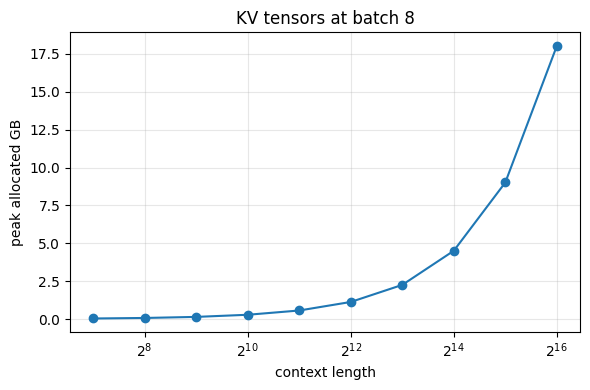

longest context that fit: 65536


In [26]:
# peak allocated GB against context length
ok = [row for row in kv_rows if not row["oom"]] if "kv_rows" in dir() else []
if ok:
    plt.figure(figsize=(6, 4))
    plt.plot([row["context"] for row in ok], [row["peak_allocated_gb"] for row in ok], marker="o")
    plt.xscale("log", base=2)
    plt.xlabel("context length")
    plt.ylabel("peak allocated GB")
    plt.title("KV tensors at batch 8")
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.savefig(FIG_DIR / "kv_cache.png", dpi=140)
    plt.show()
    print("longest context that fit:", ok[-1]["context"])
else:
    print("KV plot waits for the CUDA run")


## Part E — summary

GPU-hours for one full fine-tune are the baseline training seconds divided by 3600. The configuration I would keep is the fastest run whose test accuracy stays within 1.5 points of the baseline. This is the HW4.5 summary. It is not an HW5 baseline.


In [27]:
# write METRICS.md and append RUN_LOG.txt from the cells above
def fmt(value, digits):
    if value is None:
        return "—"
    try:
        return f"{float(value):.{digits}f}"
    except (TypeError, ValueError):
        return "—"

if "baseline_run" not in dir() or baseline_run.get("oom"):
    print("METRICS.md stays as the pre-run note until the baseline cell has run on CUDA.")
else:
    test = baseline_run["test_best_val_epoch"]
    hours = baseline_run["train_seconds"] / 3600.0
    ran_part_a = "part_a" in dir() and part_a
    base_max = next((row["batch_size"] for row in reversed(part_a) if not row.get("oom")), BASE_BATCH) if ran_part_a else BASE_BATCH
    candidates = [{
        "name": "Baseline (HW4 settings)",
        "samples_per_sec": baseline_run["samples_per_sec"],
        "peak_allocated_gb": baseline_run["peak_allocated_gb"],
        "train_seconds": baseline_run["train_seconds"],
        "test_accuracy": test["accuracy"],
    }]
    if "part_b" in dir():
        for key in ("amp", "checkpoint", "adam8bit", "combo"):
            row = part_b.get(key) or {}
            if row.get("test_accuracy") is not None and not row.get("failed"):
                candidates.append(row)
    usable = [row for row in candidates if row["test_accuracy"] >= test["accuracy"] - 0.015]
    choice = max(usable or candidates, key=lambda row: row["samples_per_sec"])
    print(f"GPU-hours = {baseline_run['train_seconds']:.1f} / 3600 = {hours:.4f}")
    print("choice:", choice["name"], fmt(choice["samples_per_sec"], 1), "samp/s", fmt(choice["peak_allocated_gb"], 2), "GB")
    note(f"gpu-hours {hours:.4f} choice {choice['name']}")

    lines = [
        "# METRICS — DATA 266 HW4.5",
        "",
        "Sneha Singh",
        "SID4 = 0670 | SEED = 670 | SLICE = 670 | HP_ID = 4 | CLS_A = 0 | CLS_B = 5",
        "",
        "Part C skipped (optional).",
        "",
        "This block is the HW4.5 summary. It is not an HW5 baseline.",
        "",
        f"Chosen configuration: {choice['name']}. Peak allocated {fmt(choice.get('peak_allocated_gb'), 2)} GB, {fmt(choice.get('samples_per_sec'), 1)} samples/s, wall-clock {fmt(choice.get('train_seconds'), 1)} s, test accuracy {fmt(choice.get('test_accuracy'), 4)}.",
        f"One baseline fine-tune: {fmt(baseline_run['train_seconds'], 1)} s / 3600 = {hours:.4f} GPU-hours.",
        "",
        f"Rows {rows[0]['row_index']}–{rows[-1]['row_index']} inclusive. Split {len(train_rows)}/{len(val_rows)}/{len(test_rows)}.",
        "",
        "| Epoch | Train loss | Val loss | Val accuracy | Seconds |",
        "|------:|-----------:|---------:|-------------:|--------:|",
    ]
    for row in baseline_run["history"]:
        lines.append(f"| {row['epoch']} | {fmt(row['train_loss'], 4)} | {fmt(row.get('val_loss'), 4)} | {fmt(row.get('val_accuracy'), 4)} | {fmt(row['seconds'], 1)} |")
    lines += ["", "| Class | Precision | Recall | Support |", "|---|---:|---:|---:|"]
    for row in test["per_class"]:
        lines.append(f"| {row['label']} | {fmt(row['precision'], 4)} | {fmt(row['recall'], 4)} | {row['support']} |")
    lines.append("")
    lines.append(f"Worst class: {test['worst_class']}.")
    lines.append("")
    lines.append("| Technique | Max batch | Throughput (samp/s) | Peak memory (GB) | Eval accuracy |")
    lines.append("|---|---:|---:|---:|---:|")
    lines.append(f"| Baseline (HW4 settings) | {base_max} | {fmt(baseline_run['samples_per_sec'], 1)} | {fmt(baseline_run['peak_allocated_gb'], 2)} | {fmt(test['accuracy'], 4)} |")
    if "part_b" in dir():
        for key, label in (
            ("amp", "Mixed precision"),
            ("checkpoint", "Gradient checkpointing"),
            ("accum", "Gradient accumulation"),
            ("adam8bit", "8-bit optimiser"),
            ("combo", "Best combination"),
        ):
            row = part_b.get(key) or {}
            if row.get("failed") or row.get("test_accuracy") is None:
                lines.append(f"| {label} | — | — | — | did not finish |")
            else:
                shown = f"{ACCUM_PHYSICAL * ACCUM_STEPS} (physical {ACCUM_PHYSICAL})" if key == "accum" else row.get("max_batch")
                lines.append(f"| {label} | {shown} | {fmt(row.get('samples_per_sec'), 1)} | {fmt(row.get('peak_allocated_gb'), 2)} | {fmt(row.get('test_accuracy'), 4)} |")
    lines.append("")
    lines.append("Part C skipped (optional).")
    lines.append("")
    (ROOT / "METRICS.md").write_text("\n".join(lines) + "\n")
    stamp = time.strftime("%Y-%m-%d %H:%M:%S UTC", time.gmtime())
    with (ROOT / "RUN_LOG.txt").open("a") as handle:
        handle.write(f"\n===== {stamp}  notebook =====\n")
        handle.write("\n".join(LOG) + "\n")
    print("wrote METRICS.md and appended RUN_LOG.txt")
    save_to_drive()


GPU-hours = 113.1 / 3600 = 0.0314
choice: Best combination 222.0 samp/s 1.64 GB
gpu-hours 0.0314 choice Best combination
wrote METRICS.md and appended RUN_LOG.txt
saving into Drive folder: HW-4.5
saved to /content/drive/MyDrive/HW-4.5
  METRICS.md  (1343 bytes)
  RUN_LOG.txt  (3058 bytes)
  checkpoints/bert_baseline/config.json  (969 bytes)
  checkpoints/bert_baseline/model.safetensors  (437961700 bytes)
  checkpoints/bert_baseline/tokenizer.json  (711661 bytes)
  checkpoints/bert_baseline/tokenizer_config.json  (351 bytes)
  data/twitter_slice.jsonl  (761653 bytes)
  figures/baseline_loss.png  (40275 bytes)
  figures/confusion.png  (26987 bytes)
  figures/kv_cache.png  (35223 bytes)
  figures/part_a_throughput.png  (31329 bytes)


## Save to Drive

Colab deletes `/content` when the runtime stops. This cell copies the working folder into My Drive. The baseline cell already copied the checkpoint, so a disconnect after that still keeps the HW4.a run.


In [28]:
# copy metrics, figures, the log, and the checkpoint into Google Drive
save_to_drive()


saving into Drive folder: HW-4.5
saved to /content/drive/MyDrive/HW-4.5
  METRICS.md  (1343 bytes)
  RUN_LOG.txt  (3058 bytes)
  checkpoints/bert_baseline/config.json  (969 bytes)
  checkpoints/bert_baseline/model.safetensors  (437961700 bytes)
  checkpoints/bert_baseline/tokenizer.json  (711661 bytes)
  checkpoints/bert_baseline/tokenizer_config.json  (351 bytes)
  data/twitter_slice.jsonl  (761653 bytes)
  figures/baseline_loss.png  (40275 bytes)
  figures/confusion.png  (26987 bytes)
  figures/kv_cache.png  (35223 bytes)
  figures/part_a_throughput.png  (31329 bytes)
